# Task


1.   Fine tuning the BERT model for sentiment analysis task using the training
dataset, and evaluating it on the test dataset.
2.   Number of nodes in the hidden layer:  100 for Task



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset,WeightedRandomSampler
from torch.nn.utils.rnn import pad_sequence
from google.colab import drive
from collections import Counter
from transformers import BertTokenizer, BertModel
from sklearn.metrics import confusion_matrix,classification_report
torch.manual_seed(42)

In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [ ]:

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load data

In [ ]:
test_df = pd.read_csv('/content/drive/MyDrive/Assignment_2_Dataset/Task 3/Data 3/test.csv')
train_df = pd.read_csv('/content/drive/MyDrive/Assignment_2_Dataset/Task 3/Data 3/train.csv')
GLOVE_PATH='/content/drive/MyDrive/Assignment_2_Dataset/Task 3/glove.6B.200d.txt'


In [ ]:

test_df['sentiment']= test_df['sentiment'].map({'Positive':0,'Negative':1})
train_df['sentiment']= train_df['sentiment'].map({'Positive':0,'Negative':1})

In [ ]:
pos_sample= train_df['sentiment'].value_counts()[0]
neg_sample = train_df['sentiment'].value_counts()[1]
pos_sample,neg_sample

(np.int64(404), np.int64(5196))

In [ ]:
test_df,train_df

(         id  sentiment                                              tweet
 0     12203          1  eeeee love paydays lol, great thing about youn...
 1     14628          1   @user yoga staerðªð»â¨#yoga #exercise #h...
 2     25641          1         #strong #weak #happy   we all have a #hea 
 3     26507          1  "happy" by pharrell williams    #pharrellwilli...
 4     20805          1  sick  #badger #dorset wife brought gloves &amp...
 ...     ...        ...                                                ...
 1395  25549          1  the treasures of #wisconsin libraries, museums...
 1396   8078          1         can't wait for @user at the o2 tomorrow   
 1397  11121          1  fever - official movie teaser | rajeev khandel...
 1398  25628          1  i am thankful for peace. #thankful #positive     
 1399  18490          1            best 10 minutes my whole week ðð 
 
 [1400 rows x 3 columns],
          id  sentiment                                              twe

#Prepare Data for Tarining

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def prepare_dataloader(df, tokenizer, batch_size=32, sampler=None):

    encoded = tokenizer(
        df['tweet'].tolist(),
        add_special_tokens=True,
        max_length=64,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    dataset = TensorDataset(
        encoded['input_ids'],
        encoded['attention_mask'],
        torch.tensor(df['sentiment'].values).float()
    )

    return DataLoader(dataset, batch_size=batch_size, sampler=sampler)

# Weighted Random Sampler

In [ ]:

pos_sample= test_df['sentiment'].value_counts()[0]
neg_sample = test_df['sentiment'].value_counts()[1]
total_samples = pos_sample + neg_sample
weight_for_majority = total_samples / neg_sample  # ~1.07
weight_for_minority = total_samples / pos_sample   # ~13.86

sample_weights = []
for label in test_df['sentiment']:
    if label == 1:
        sample_weights.append(weight_for_majority)
    elif label == 0:
        sample_weights.append(weight_for_minority)

sampler_test = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

In [ ]:

train_loader = prepare_dataloader(train_df, tokenizer, batch_size=32, sampler=sampler_train)
test_loader = prepare_dataloader(test_df, tokenizer, batch_size=32)

#RNN Architecture


In [ ]:
class BERTSentiment(nn.Module):
    def __init__(self, hidden_dim=100):
        super().__init__()
        self.bert = BertModel.from_pretrained('bert-base-uncased')

        self.fc1 = nn.Linear(self.bert.config.hidden_size, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        # pooled_output represents the [CLS] token context
        pooled_output = outputs.pooler_output
        x = self.relu(self.fc1(pooled_output))
        return self.fc2(x)

Model Define

#Training DATA

In [ ]:
def train_model(model, train_loader, criterion, optimizer, device, epochs=4):
    for epoch in range(epochs):
        model.train()
        total_loss = 0


        for batch_ids, batch_mask, batch_y in train_loader:
            batch_ids = batch_ids.to(device)
            batch_mask = batch_mask.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()


            predictions = model(batch_ids, batch_mask).squeeze()

            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1:02d}/{epochs} | Average Loss: {avg_loss:.4f}")

    print("Training Complete!")

# Evalute Model

In [ ]:
def evaluate_model(model, test_loader, device, type_str):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_ids, batch_mask, batch_y in test_loader:
            batch_ids = batch_ids.to(device)
            batch_mask = batch_mask.to(device)
            batch_y = batch_y.to(device)

            outputs = model(batch_ids, batch_mask).squeeze()
            predictions = (torch.sigmoid(outputs) > 0.5).float()

            total += batch_y.size(0)
            correct += (predictions == batch_y).sum().item()

    accuracy = 100 * correct / total
    print(f'{type_str} Accuracy: {accuracy:.2f}%')
    return accuracy

#Plot COnfusion MAtrix

In [ ]:
def plot_confusion_matrix(model, loader, device, mode):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for batch_ids, batch_mask, batch_y in loader:
            batch_ids = batch_ids.to(device)
            batch_mask = batch_mask.to(device)

            outputs = model(batch_ids, batch_mask).squeeze()
            predictions = (torch.sigmoid(outputs) > 0.5).float()

            y_true.extend(batch_y.numpy())
            y_pred.extend(predictions.cpu().numpy())

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
                xticklabels=['Positive', 'Negative'],
                yticklabels=['Positive', 'Negative'])
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.title(f'Confusion Matrix for {mode}')
    plt.show()

    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred, target_names=['Positive', 'Negative'], zero_division=0))

In [ ]:
torch.manual_seed(42)
model = BERTSentiment(hidden_dim=100)
model.to(device)


optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
criterion = nn.BCEWithLogitsLoss()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Call Trainign Function

In [ ]:
# Call the training function
train_model(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=4
)

Epoch 01/4 | Average Loss: 0.2918
Epoch 02/4 | Average Loss: 0.0856
Epoch 03/4 | Average Loss: 0.0409
Epoch 04/4 | Average Loss: 0.0176
Training Complete!


In [ ]:
print("\n--- Evaluation on Train Data ---")
train_accuracy = evaluate_model(model, train_loader, device, "Train")



--- Evaluation on Train Data ---
Train Accuracy: 99.88%


In [ ]:
print("\n--- Evaluation on Test Data ---")
test_accuracy = evaluate_model(model, test_loader, device, "Test")



--- Evaluation on Test Data ---
Test Accuracy: 97.21%



--- Confusion Matrix for Train Data ---


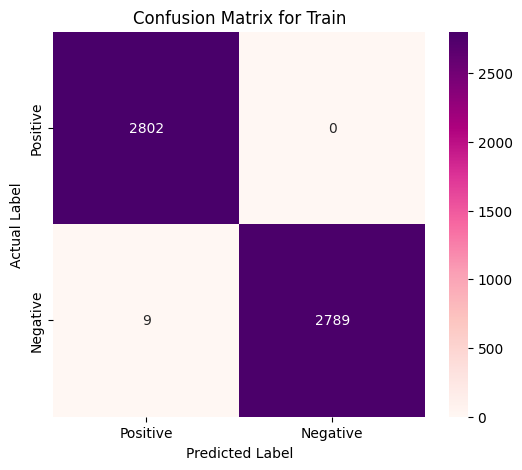


--- Classification Report ---
              precision    recall  f1-score   support

    Positive       1.00      1.00      1.00      2802
    Negative       1.00      1.00      1.00      2798

    accuracy                           1.00      5600
   macro avg       1.00      1.00      1.00      5600
weighted avg       1.00      1.00      1.00      5600



In [ ]:
print("\n--- Confusion Matrix for Train Data ---")
plot_confusion_matrix(model, train_loader, device, "Train")


--- Confusion Matrix for Test Data ---


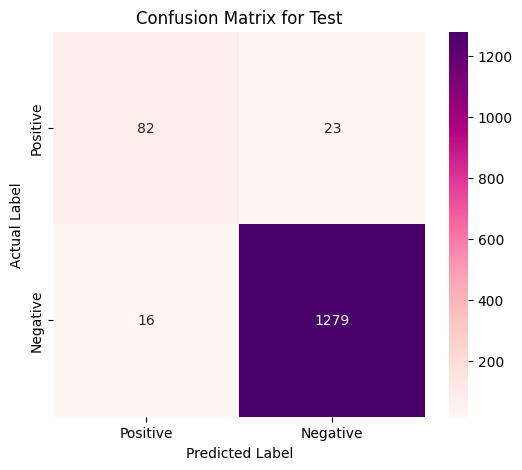


--- Classification Report ---
              precision    recall  f1-score   support

    Positive       0.84      0.78      0.81       105
    Negative       0.98      0.99      0.98      1295

    accuracy                           0.97      1400
   macro avg       0.91      0.88      0.90      1400
weighted avg       0.97      0.97      0.97      1400



In [ ]:
print("\n--- Confusion Matrix for Test Data ---")
plot_confusion_matrix(model, test_loader, device, "Test")

In [ ]:
def print_examples(name, loader, num=5):
    model.eval()
    label_map = {1: 'Negative', 0: 'Positive'}
    print(f"--- {num} {name.upper()} EXAMPLES ---")

    with torch.no_grad():
        for ids, mask, y in loader:

            outputs = model(ids.to(device), mask.to(device)).squeeze()
            preds = (torch.sigmoid(outputs) > 0.5).int().cpu().numpy()


            for i in range(num):
                text = tokenizer.decode(ids[i], skip_special_tokens=True)
                p, a = label_map[preds[i]], label_map[int(y[i])]
                print(f"{i+1}. Text: {text}\n   Predicted: {p} | Ground Truth: {a}\n")
            break

test_loader_x = prepare_dataloader(test_df, tokenizer, batch_size=32,sampler=sampler_test)
print_examples("training", train_loader)
print_examples("test", test_loader_x)

--- 5 TRAINING EXAMPLES ---
1. Text: @ user this man ran for governor of ny, the state with the biggest african - american population # a¦
   Predicted: Positive | Ground Truth: Positive

2. Text: book - enduring conviction : fred korematsu & amp ; his quest for # justice # humanrights hta¦
   Predicted: Positive | Ground Truth: Positive

3. Text: keep people in your life who truely # love you, # motivate you, # encourage you, # enhances you, & amp ; makes you # simple ðð¾ðð¾ðð¾
   Predicted: Negative | Ground Truth: Negative

4. Text: we have to do this. need to change profiling, # economicapahied, # hatespeech and get service to the poor. a¦
   Predicted: Positive | Ground Truth: Positive

5. Text: another happy bihday boy! # mariascakeboutique # bihdayboy # mumblesspottedbag # cake
   Predicted: Negative | Ground Truth: Negative

--- 5 TEST EXAMPLES ---
1. Text: every news journal ' s top story is about orlando except the @ user which features a story on back - country access. # cut